In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files


In [2]:
archivo = files.upload()

nombre_archivo = list(archivo.keys())[0]

df = pd.read_csv(nombre_archivo, sep=None, engine="python", encoding="utf-8-sig")

print(df.head())

Saving SP1_2025_2026.csv to SP1_2025_2026.csv
   Div        Date   Time    HomeTeam   AwayTeam  FTHG  FTAG FTR  HTHG  HTAG  \
0  SP1  15/08/2025  18:00      Girona  Vallecano     1     3   A     0     3   
1  SP1  15/08/2025  20:30  Villarreal     Oviedo     2     0   H     2     0   
2  SP1  16/08/2025  18:30    Mallorca  Barcelona     0     3   A     0     2   
3  SP1  16/08/2025  20:30      Alaves    Levante     2     1   H     1     0   
4  SP1  16/08/2025  20:30    Valencia   Sociedad     1     1   D     0     0   

   ... B365CAHH  B365CAHA  PCAHH  PCAHA  MaxCAHH  MaxCAHA  AvgCAHH  AvgCAHA  \
0  ...      2.1      1.78   1.97   1.95     2.10     1.80     1.95     1.75   
1  ...      1.9      1.95   1.93   2.00     1.94     1.96     1.82     1.87   
2  ...      2.0      1.85   1.88   2.05     2.00     1.93     1.90     1.86   
3  ...      1.8      2.05   1.86   2.07     1.80     2.07     1.70     2.00   
4  ...      2.1      1.78   2.13   1.81     2.10     1.78     1.96     1.74   

In [3]:

print("Columnas de la base de datos:")
print(df.columns)

print("\nCantidad de partidos:")
print(len(df))

print("\nEquipos registrados:")
print(sorted(set(df["HomeTeam"].dropna()) | set(df["AwayTeam"].dropna())))


Columnas de la base de datos:
Index(['Div', 'Date', 'Time', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR',
       'HTHG', 'HTAG',
       ...
       'B365CAHH', 'B365CAHA', 'PCAHH', 'PCAHA', 'MaxCAHH', 'MaxCAHA',
       'AvgCAHH', 'AvgCAHA', 'BFECAHH', 'BFECAHA'],
      dtype='object', length=131)

Cantidad de partidos:
380

Equipos registrados:
['Alaves', 'Ath Bilbao', 'Ath Madrid', 'Barcelona', 'Betis', 'Celta', 'Elche', 'Espanol', 'Getafe', 'Girona', 'Levante', 'Mallorca', 'Osasuna', 'Oviedo', 'Real Madrid', 'Sevilla', 'Sociedad', 'Valencia', 'Vallecano', 'Villarreal']


In [4]:

equipo = "Getafe"

# Partidos donde Getafe juega como local
getafe_local = df[df["HomeTeam"] == equipo].copy()

# Partidos donde Getafe juega como visitante
getafe_visitante = df[df["AwayTeam"] == equipo].copy()

print("Partidos de Getafe como local:", len(getafe_local))
print("Partidos de Getafe como visitante:", len(getafe_visitante))


Partidos de Getafe como local: 19
Partidos de Getafe como visitante: 19


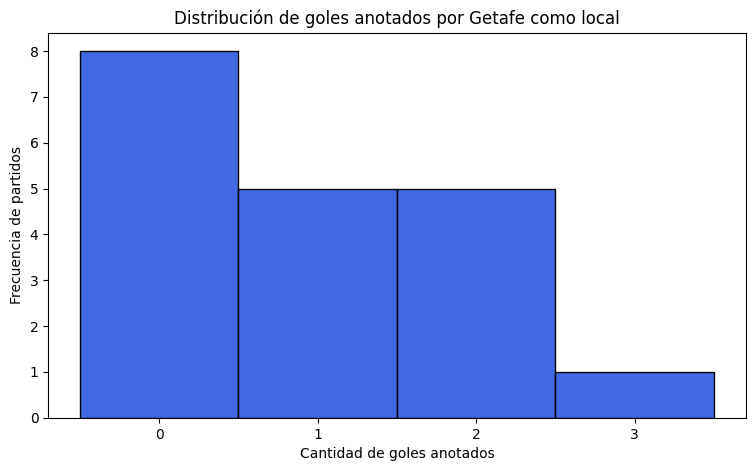

In [5]:

goles_local = getafe_local["FTHG"].dropna()

plt.figure(figsize=(9, 5))

plt.hist(goles_local,
         bins=np.arange(-0.5, goles_local.max() + 1.5, 1),
         color="royalblue",
         edgecolor="black")

plt.title("Distribución de goles anotados por Getafe como local")
plt.xlabel("Cantidad de goles anotados")
plt.ylabel("Frecuencia de partidos")

plt.xticks(range(int(goles_local.max()) + 1))
plt.show()


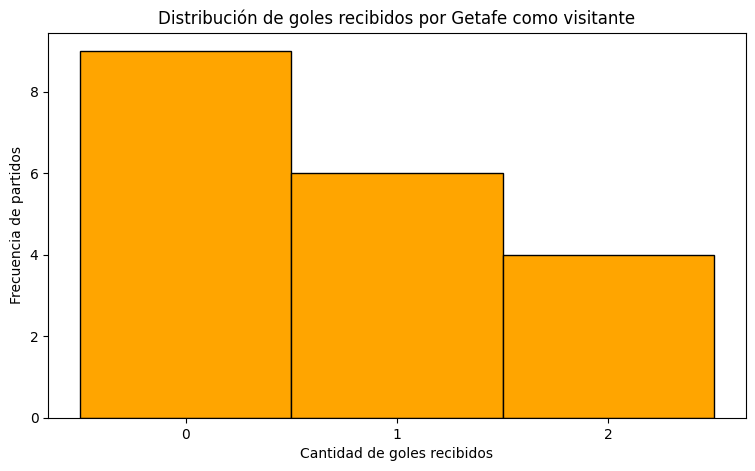

In [6]:

goles_recibidos = getafe_visitante["FTAG"].dropna()

plt.figure(figsize=(9, 5))

plt.hist(goles_recibidos,
         bins=np.arange(-0.5, goles_recibidos.max() + 1.5, 1),
         color="orange",
         edgecolor="black")

plt.title("Distribución de goles recibidos por Getafe como visitante")
plt.xlabel("Cantidad de goles recibidos")
plt.ylabel("Frecuencia de partidos")

plt.xticks(range(int(goles_recibidos.max()) + 1))
plt.show()


El primer histograma muestra la distribución de los goles anotados por el Getafe cuando juega como local. Se observa que la cantidad de goles más frecuente es 0, lo que indica que, en la mayoría de sus partidos en casa, el equipo no logró marcar. Por otro lado, el segundo histograma representa los goles recibidos por el equipo cuando juega como visitante, donde destaca también la frecuencia de 0 goles recibidos, reflejando una alta cantidad de partidos con la portería a cero fuera de casa. Al comparar ambos gráficos, podemos identificar diferencias significativas entre el rendimiento ofensivo del Getafe como local y su comportamiento defensivo fuera de casa. En general, estos resultados permiten reconocer los patrones de anotación y recepción de goles del equipo en ambas condiciones.

In [7]:
resultados = getafe_local["FTR"].value_counts()

victorias = resultados.get("H", 0)
empates = resultados.get("D", 0)
derrotas = resultados.get("A", 0)

print("Victorias:", victorias)
print("Empates:", empates)
print("Derrotas:", derrotas)


Victorias: 8
Empates: 3
Derrotas: 8


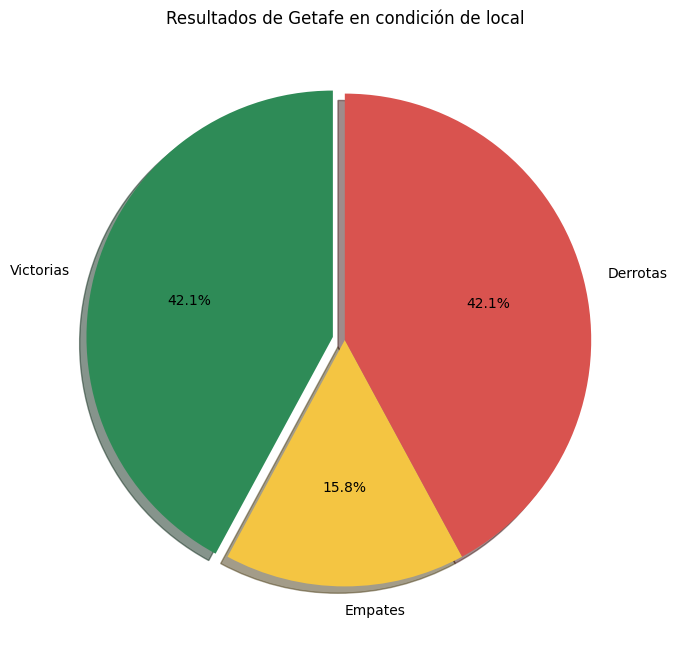

In [8]:

etiquetas = ["Victorias", "Empates", "Derrotas"]

valores = [victorias, empates, derrotas]

colores = ["#2E8B57", "#F4C542", "#D9534F"]

plt.figure(figsize=(8, 8))

plt.pie(valores,
        labels=etiquetas,
        autopct="%1.1f%%",
        colors=colores,
        shadow=True,
        startangle=90,
        explode=(0.05, 0, 0))

plt.title("Resultados de Getafe en condición de local")
plt.show()


El gráfico muestra la distribución de los resultados obtenidos por el Getafe cuando juega como local. Se observa un empate técnico en la mayor proporción: tanto las victorias como las derrotas representan un 42.1% del total de los partidos. Por otro lado, los empates constituyen la menor proporción, con apenas un 15.8%, lo que indica que es el resultado menos frecuente para el equipo en casa. En síntesis, la distribución revela un desempeño local muy polarizado, donde el equipo o gana o pierde, pero rara vez reparte puntos.

In [9]:

# Calculamos el promedio de tarjetas amarillas recibidas por cada equipo como visitante

promedio_tarjetas = df.groupby("AwayTeam")["AY"].mean()

# Redondear los promedios al número entero más cercano
promedio_tarjetas = promedio_tarjetas.round().astype(int)

print(promedio_tarjetas.sort_values(ascending=False))


AwayTeam
Alaves         3
Villarreal     3
Getafe         3
Espanol        3
Sociedad       3
Vallecano      3
Sevilla        3
Ath Bilbao     2
Barcelona      2
Ath Madrid     2
Celta          2
Betis          2
Mallorca       2
Levante        2
Girona         2
Elche          2
Real Madrid    2
Oviedo         2
Osasuna        2
Valencia       2
Name: AY, dtype: int64


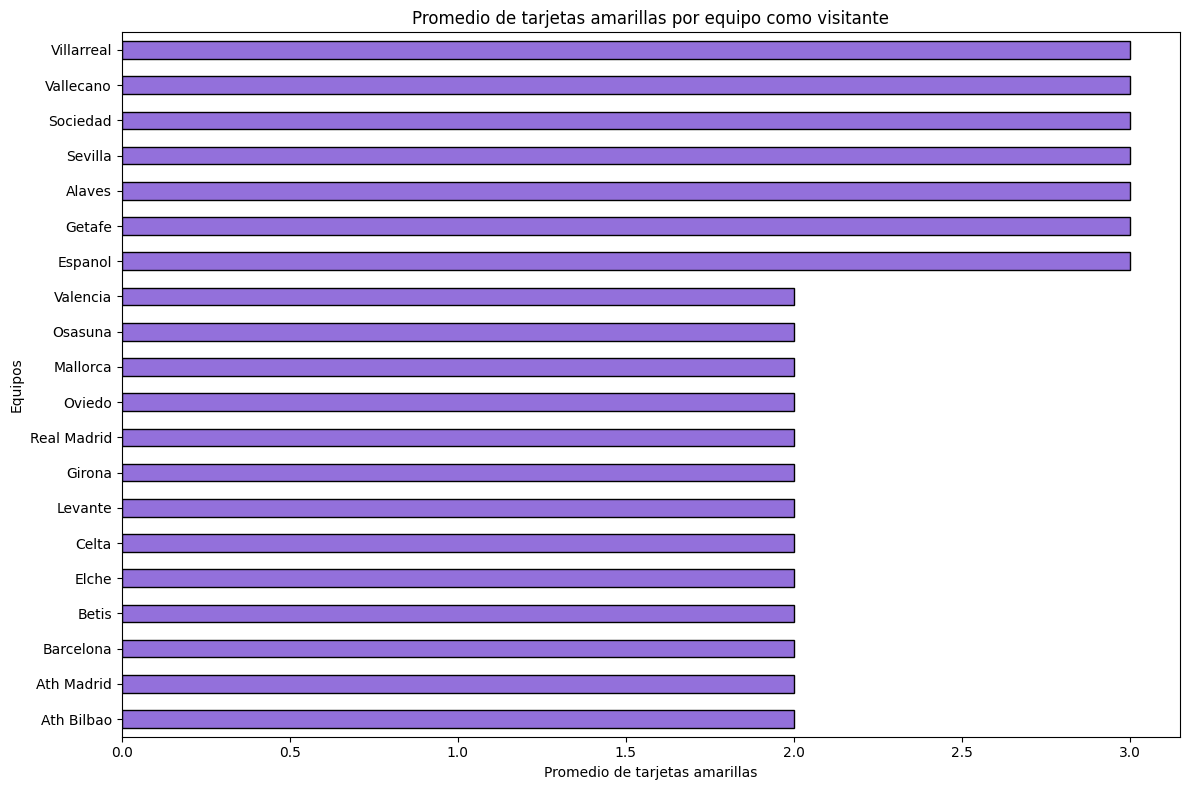

In [10]:

plt.figure(figsize=(12, 8))

promedio_tarjetas.sort_values().plot(
    kind="barh",
    color="mediumpurple",
    edgecolor="black"
)

plt.title("Promedio de tarjetas amarillas por equipo como visitante")
plt.xlabel("Promedio de tarjetas amarillas")
plt.ylabel("Equipos")

plt.tight_layout()
plt.show()


El gráfico de barras presenta el promedio de tarjetas amarillas recibidas por los equipos de La Liga cuando juegan como visitantes. Se observa que siete equipos (encabezados por el Villarreal) registran el promedio más alto, con exactamente 3.0 tarjetas amarillas por partido fuera de casa. En contraste, el resto de los equipos de la lista (como el Athletic Bilbao, Barcelona o Real Madrid) presentan un promedio menor, situado en 2.0 tarjetas. Es importante destacar que el Getafe se encuentra en el grupo de mayor amonestación (3.0). Esta comparación permite identificar que, en esta muestra, la disciplina fuera de casa se divide claramente en dos bloques bien diferenciados.